# Step 2: Did Harbour's 15% campaign pay for itself?

**Business question.** Harbour ran a 15% discount on cold coffee and desserts in two 8-day campaigns (12–19 March and 12–19 May 2026). Did those campaigns bring in enough extra business to cover the discount, and should Stories run them again in the same form?

**Short answer (details and evidence below).** No measurable benefit was found. Harbour gave away about **$470** in discounts. Sales of the promoted items rose by about **2%** (+11 units). That is smaller than normal day-to-day noise and far below the roughly **+159 units** the campaign needed to break even. Transactions, other items and the week after the campaign show no offsetting gain. About 93% of identified campaign buyers had bought before. The recommendation is to stop untargeted 15% campaigns of this design. Before using any discount again, Stories should run the randomized test described in Section 9.

This notebook keeps **observed facts**, **estimates** and **assumptions** separate, and lists the approaches we rejected and why.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw" / "stories_transactions.csv"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA)
raw["Date"] = pd.to_datetime(raw["Date"])
print(f"{len(raw):,} lines, {raw['Transaction ID'].nunique():,} purchases, {raw['Date'].min().date()} to {raw['Date'].max().date()}")

51,177 lines, 33,887 purchases, 2026-01-01 to 2026-06-30


## 1. Observed facts: what the campaign was

The data has no campaign label. We define the campaign from the data itself: every line with a 15% discount rate.

In [2]:
P = raw[raw["Discount Rate"] == 0.15]
CAMP_DAYS = pd.DatetimeIndex(sorted(P["Date"].unique()))
ITEMS = sorted(P["Product"].unique())

print("Branches with 15% lines:", P["Branch"].unique().tolist())
print("Campaign days:", len(CAMP_DAYS), "->", [d.strftime("%d %b") for d in CAMP_DAYS])
print("Promoted products:", ITEMS)
print("Categories:", sorted(P["Category"].unique()))

on_days = raw[(raw.Branch == "Harbour") & raw.Product.isin(ITEMS) & raw.Date.isin(CAMP_DAYS)]
print("\nHarbour lines of promoted products on campaign days:", len(on_days),
      "| discount rates seen:", on_days["Discount Rate"].value_counts().to_dict())
print("15% lines outside those days/products:", len(P) - len(P[P.Date.isin(CAMP_DAYS) & P.Product.isin(ITEMS)]))

discount_given = (P["Quantity"] * P["Unit Price (USD)"] * 0.15).sum()
print(f"\nDiscount given (list price x 15%): ${discount_given:,.2f} on {P['Quantity'].sum()} units")

Branches with 15% lines: ['Harbour']
Campaign days: 16 -> ['12 Mar', '13 Mar', '14 Mar', '15 Mar', '16 Mar', '17 Mar', '18 Mar', '19 Mar', '12 May', '13 May', '14 May', '15 May', '16 May', '17 May', '18 May', '19 May']
Promoted products: ['Brownie', 'Cheesecake Slice', 'Coffee Frappe', 'Cold Brew', 'Frozen Yoghurt Cup', 'Iced Americano', 'Iced Latte', 'Iced Mocha', 'Tiramisu Cup']
Categories: ['Cold Coffee', 'Desserts']

Harbour lines of promoted products on campaign days: 504 | discount rates seen: {0.15: 504}
15% lines outside those days/products: 0

Discount given (list price x 15%): $472.08 on 542 units


**Observed:** the 15% rate appears only at Harbour, only on 9 products (5 cold coffees and 4 desserts), and only on 16 days in two blocks of 8 consecutive days. On those days, *every* Harbour sale of those products received 15%. This is consistent with a planned, branch-wide promotion rather than a loyalty or staff discount. **Assumption:** this is the campaign as Stories ran it. We have no campaign brief, so its objective, advertising and any marketing cost are unknown.

## 2. Rejected approach: comparing discounted and full-price baskets

The obvious first analysis compares the average discounted purchase with the average full-price purchase. We rejected it:

In [3]:
tx = (raw[raw.Branch == "Harbour"].groupby("Transaction ID")
      .agg(rate=("Discount Rate", "max"), items=("Quantity", "sum"), gp=("Line Gross Profit (USD)", "sum")))
display(tx.groupby("rate")[["items", "gp"]].mean().round(2))
mix = (raw[raw.Branch == "Harbour"].groupby(["Discount Rate", "Category"]).size()
       .groupby(level=0).transform(lambda s: s / s.sum()).unstack(0).round(3))
display(mix)

,items,gp
rate,,
0.00,1.57,5.97
0.10,1.81,6.20
0.15,1.78,5.72


Discount Rate,0.00,0.10,0.15
Category,,,
Bakery,0.230,0.217,NaN
Breakfast,0.046,0.044,NaN
Cold Coffee,0.137,0.132,0.643
Cold Drinks,0.103,0.098,NaN
Desserts,0.072,0.068,0.357
Hot Coffee,0.164,0.190,NaN
Matcha & Tea,0.153,0.167,NaN
Meals,0.028,0.019,NaN
Sandwiches,0.067,0.065,NaN


A comparison like this says nothing about cause. The 15% baskets contain only cold coffee and desserts, while full-price baskets contain everything, so the gap reflects **product mix and customer selection**, not the discount's effect. It also cannot show whether the discount brought in *extra* sales or only discounted sales that would have happened anyway. We need a counterfactual: what Harbour would have sold on those days **without** the campaign.

## 3. Method: Harbour compared with the other branches on the same days

**Design (comparative interrupted series / difference-in-differences).** For each campaign day we predict Harbour's sales from what Garden and Uptown sold that **same day**. We use Harbour's usual ratio to them on the **same weekday** within ±28 days, excluding campaign days and the 7 days after each campaign. Using the other branches on the same day removes chain-wide effects (growth from January to June, weather, holidays, the strong Tuesdays). Matching the weekday removes weekly patterns.

`effect = actual Harbour − (Garden + Uptown that day) × baseline ratio`

We measure promoted items and other items separately, so we can see the direct effect, any cross-selling and any cannibalisation.

**Key assumption A1:** without the campaign, Harbour's ratio to the other branches would have stayed at its usual level. Section 5 checks how much this ratio moves on ordinary days. **Assumption A2:** the campaign did not change sales at Garden or Uptown. Section 7 examines this, because many customers visit several branches.

In [4]:
def build_daily(df):
    df = df.assign(seg=np.where(df.Product.isin(ITEMS), "camp", "other"),
                   side=np.where(df.Branch == "Harbour", "H", "C"))
    g = (df.groupby(["Date", "side", "seg"])
           .agg(units=("Quantity", "sum"), gp=("Line Gross Profit (USD)", "sum"))
           .unstack(["side", "seg"]))
    g.columns = ["_".join(c) for c in g.columns]
    t = df.groupby(["Date", "side"])["Transaction ID"].nunique().unstack()
    g["tx_H"], g["tx_C"] = t["H"], t["C"]
    g["gp_H"] = g.gp_H_camp + g.gp_H_other
    g["gp_C"] = g.gp_C_camp + g.gp_C_other
    return g.fillna(0)

def masks(index):
    camp = index.isin(CAMP_DAYS)
    post = np.zeros(len(index), bool)
    for end in [CAMP_DAYS[7], CAMP_DAYS[-1]]:
        post |= (index > end) & (index <= end + pd.Timedelta(days=7))
    return camp, post, ~camp & ~post

def effect(daily, h, c, window, base):
    total = 0.0
    for day in daily.index[window]:
        local = base & (np.abs((daily.index - day).days) <= 28) & (daily.index.dayofweek == day.dayofweek)
        ratio = daily.loc[local, h].sum() / daily.loc[local, c].sum()
        total += daily.loc[day, h] - ratio * daily.loc[day, c]
    return total

METRICS = {
    "Promoted items, units":    ("units_H_camp", "units_C_camp"),
    "Other items, units":       ("units_H_other", "units_C_other"),
    "Purchases (transactions)": ("tx_H", "tx_C"),
    "Promoted items, gross profit $": ("gp_H_camp", "gp_C_camp"),
    "Other items, gross profit $":    ("gp_H_other", "gp_C_other"),
    "All Harbour gross profit $":     ("gp_H", "gp_C"),
}

daily = build_daily(raw)
CAMP, POST, CLEAN = masks(daily.index)
rows = []
for name, (h, c) in METRICS.items():
    e = effect(daily, h, c, CAMP, CLEAN)
    actual = daily.loc[CAMP, h].sum()
    rows.append({"metric": name, "actual (16 days)": actual, "expected without campaign": actual - e,
                 "estimated effect": e, "effect %": e / (actual - e) * 100})
results = pd.DataFrame(rows).set_index("metric")
results.round(1)

,actual (16 days),expected without campaign,estimated effect,effect %
metric,,,,
"Promoted items, units",542.0,531.3,10.7,2.0
"Other items, units",1862.0,1929.1,-67.1,-3.5
Purchases (transactions),1499.0,1528.5,-29.5,-1.9
"Promoted items, gross profit $",1609.7,2028.5,-418.8,-20.6
"Other items, gross profit $",7022.7,7138.1,-115.4,-1.6
All Harbour gross profit $,8632.4,9153.8,-521.4,-5.7


## 4. Picture: Harbour's share of promoted-item sales over time

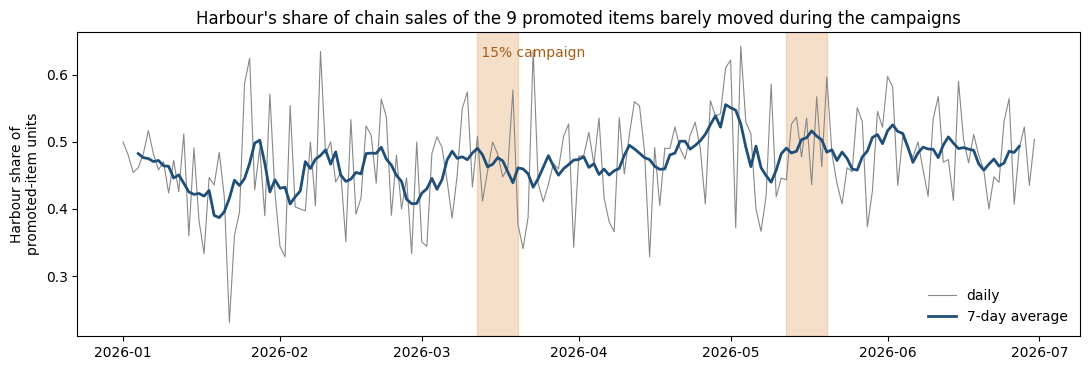

In [5]:
share = daily.units_H_camp / (daily.units_H_camp + daily.units_C_camp)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(share.index, share.values, lw=0.8, color="#888", label="daily")
ax.plot(share.index, share.rolling(7, center=True).mean(), lw=2, color="#1f4e79", label="7-day average")
for s, e in [(CAMP_DAYS[0], CAMP_DAYS[7]), (CAMP_DAYS[8], CAMP_DAYS[-1])]:
    ax.axvspan(s, e + pd.Timedelta(hours=23), color="#d9822b", alpha=0.25)
ax.text(CAMP_DAYS[0], share.max(), " 15% campaign", color="#a85c12", va="top")
ax.set_ylabel("Harbour share of\npromoted-item units")
ax.set_title("Harbour's share of chain sales of the 9 promoted items barely moved during the campaigns")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(FIG / "campaign_share.png", dpi=150); plt.show()

## 5. How large is "normal noise"? Placebo test on ordinary days

A 2% lift means little unless we know how much this measure moves when nothing happens. We apply **exactly the same method** to every block of 8 consecutive ordinary days, pretending each was a campaign. We then double the result to match the two real campaigns. This gives the spread of "effects" produced by chance alone. The placebo windows are data the method was not built on, which serves as our out-of-sample check.

In [6]:
clean_set = set(daily.index[CLEAN])
starts = [s for s in daily.index[CLEAN] if all(s + pd.Timedelta(days=i) in clean_set for i in range(8))]
plac = {name: [] for name in METRICS}
for s in starts:
    blk = (daily.index >= s) & (daily.index < s + pd.Timedelta(days=8))
    for name, (h, c) in METRICS.items():
        plac[name].append(2 * effect(daily, h, c, blk, CLEAN & ~blk))
plac = pd.DataFrame(plac)

summary = pd.DataFrame({
    "observed effect": results["estimated effect"],
    "placebo 5th pct": plac.quantile(0.05),
    "placebo 95th pct": plac.quantile(0.95),
    "share of placebos at least as large": [(plac[n].abs() >= abs(results.loc[n, "estimated effect"])).mean() for n in METRICS],
})
print(f"{len(starts)} placebo windows")
summary.round(2)

130 placebo windows


,observed effect,placebo 5th pct,placebo 95th pct,share of placebos at least as large
"Promoted items, units",10.73,-90.36,114.07,0.88
"Other items, units",-67.08,-219.78,191.16,0.59
Purchases (transactions),-29.45,-140.83,130.96,0.80
"Promoted items, gross profit $",-418.75,-354.26,434.43,0.07
"Other items, gross profit $",-115.42,-765.76,691.95,0.81
All Harbour gross profit $,-521.39,-985.16,1039.44,0.46


**Reading the table.**
- **Promoted-item units:** +11 units. About 88% of no-campaign windows produce a change at least this large, so the volume lift cannot be told apart from zero.
- **Promoted-item gross profit:** down about $419. Only about 7% of placebo windows show a change this large. This is the one clear signal, and it is about the size of the discount itself ($470).
- **Total Harbour gross profit:** down about $520, but noise is ±$1,000, so this total alone is inconclusive. The conclusion therefore rests on the break-even test in the next section, not on the total.

## 6. Break-even: how much extra volume would the campaign have needed?

Each discounted unit still earned some margin, so extra volume could in principle repay the discount.

In [7]:
gp_per_disc_unit = P["Line Gross Profit (USD)"].sum() / P["Quantity"].sum()
needed = discount_given / gp_per_disc_unit
expected_units = results.loc["Promoted items, units", "expected without campaign"]
obs = results.loc["Promoted items, units", "estimated effect"]
p95 = plac["Promoted items, units"].quantile(0.95)
upper = obs + p95  # generous upper bound: observed plus the largest typical chance swing
print(f"Gross profit per discounted unit: ${gp_per_disc_unit:.2f}")
print(f"Extra units needed to repay ${discount_given:,.0f}: {needed:.0f} (+{needed/expected_units:.0%} over expected {expected_units:.0f})")
print(f"Observed extra units: {obs:+.0f};  generous upper bound: {upper:+.0f}")
print("Break-even lift inside the plausible range?", needed <= upper)

Gross profit per discounted unit: $2.97
Extra units needed to repay $472: 159 (+30% over expected 531)
Observed extra units: +11;  generous upper bound: +125
Break-even lift inside the plausible range? False


**Result.** Breaking even needed about **+159 units (+30%)**. The observed lift was +11. Even a generous upper bound (observed plus the 95th-percentile chance swing, about +125) falls short. Other items and transactions did not rise either, so cross-selling did not make up the gap. Under assumption A1, the campaign as designed **did not pay for itself** at the gross-profit level.

## 7. Testing alternative explanations

| Alternative explanation | Check | Result |
|---|---|---|
| The campaign moved demand *later* (people came back after it ended) | Same method on the 7 days after each campaign | See below: no rebound |
| The campaign *pulled* customers from Garden/Uptown, so the control branches were depressed | If true, Harbour's estimated lift would be **too high**. The chain-wide gain would be even smaller | Makes the conclusion stronger, not weaker |
| It attracted **new** customers who will pay full price later | Share of identified campaign buyers who had already bought before | See below |
| Repeated rows (Step 1 audit) distort results | Rerun everything without exact repeats | See below |
| The discount cleared desserts that would otherwise be wasted | **Not testable**: the data has no waste or stock records | Main open risk, listed in Section 10 |

In [8]:
post_gp = effect(daily, "gp_H", "gp_C", POST, CLEAN)
post_units = effect(daily, "units_H_camp", "units_C_camp", POST, CLEAN)
print(f"Week after campaigns: Harbour gross profit {post_gp:+.0f} $, promoted units {post_units:+.0f}  (no rebound)")

ids = raw.dropna(subset=["Customer ID"])
first_seen = ids.groupby("Customer ID")["Date"].min()
def share_returning(lines):
    f = lines.dropna(subset=["Customer ID"]).groupby("Customer ID")["Date"].min()
    return (first_seen[f.index] < f).mean(), len(f)
camp_share, n1 = share_returning(P)
same_days_other = raw[(raw.Branch == "Harbour") & raw.Date.isin(CAMP_DAYS) & ~raw.Product.isin(ITEMS)]
ref_share, n2 = share_returning(same_days_other)
print(f"Identified campaign buyers already seen before: {camp_share:.1%} (n={n1})")
print(f"Comparison: Harbour non-promoted buyers on the same days: {ref_share:.1%} (n={n2})")

Week after campaigns: Harbour gross profit -287 $, promoted units -23  (no rebound)


Identified campaign buyers already seen before: 92.7% (n=289)


Comparison: Harbour non-promoted buyers on the same days: 93.4% (n=713)


In [9]:
dedup = raw.drop_duplicates()
d2 = build_daily(dedup); c2, p2, k2 = masks(d2.index)
sens = pd.DataFrame({
    "all rows": results["estimated effect"],
    "exact repeats removed": [effect(d2, h, c, c2, k2) for h, c in METRICS.values()],
}, index=list(METRICS))
sens.round(1)

,all rows,exact repeats removed
"Promoted items, units",10.7,10.2
"Other items, units",-67.1,-70.5
Purchases (transactions),-29.5,-29.5
"Promoted items, gross profit $",-418.8,-418.2
"Other items, gross profit $",-115.4,-129.2
All Harbour gross profit $,-521.4,-533.5


**Findings.**
- **Later demand:** the week after each campaign shows no rebound. Promoted-item sales were slightly *lower*, which fits mild stock-up or pull-forward, not lasting new demand.
- **New customers:** almost all identified campaign buyers were existing customers, about the same share as Harbour's non-promoted buyers on the same days. So the discount mostly went to people who were already coming. One limit: about a third of campaign lines have no customer ID.
- **Repeated rows:** removing exact repeats changes no conclusion.

## 8. What is measured, what is estimated, what is assumed

| Type | Statement |
|---|---|
| **Measured** | 15% applied only at Harbour, on 9 cold coffee and dessert items, 12–19 Mar and 12–19 May 2026; $470 discount on 542 units |
| **Measured** | Harbour's share of chain promoted-item sales barely changed on campaign days |
| **Estimated** | Extra units ≈ +11 (+2%), within the chance range; break-even needed ≈ +159 |
| **Estimated** | Net gross-profit effect is negative, about the size of the discount (−$420 on promoted items) |
| **Assumed (A1)** | Without the campaign, Harbour's ratio to Garden + Uptown would have matched nearby same-weekday days |
| **Assumed (A2)** | The campaign did not change Garden/Uptown sales. If it did, the true chain effect is *worse* |
| **Assumed (A3)** | Recorded unit costs are correct marginal costs. If true marginal costs are lower, break-even falls, but it would need a much larger lift than observed to change the decision |
| **Not observed** | Campaign goal, advertising spend, waste avoided, effect on brand or new-customer acquisition beyond 6 months |

**Which assumptions could change the action?** Only an unseen benefit could: mainly **waste avoided** on desserts, or a strategic goal such as competing with a rival opening nearby. Even at the generous upper bound of the observed lift (about +125 units, worth about $370 at $2.97 each), the campaign would still need roughly **$100 or more** of benefit not visible in this data to break even. At the central estimate, it would need about $440. If Stories' records show waste savings this large, a smaller, targeted version could be justified.

## 9. Recommendation and the practical test Stories can run

**Action.** Do not repeat untargeted, branch-wide 15% campaigns on cold coffee and desserts. Use the same budget only inside a controlled test:

1. **Randomized days at one branch.** For 6 weeks, randomly assign each day (balanced by weekday) to *offer* or *no offer*, using the same 9 items. Compare with the other branches on the same day, as here.
2. **Pre-registered success rule:** continue only if the extra gross profit on promoted *and* other items exceeds the discount cost, and the week after shows no dip.
3. **Also log** waste, stock-outs and advertising cost per day, which this dataset lacks.
4. **Cheaper alternatives to test against it:** 10% (the existing everyday rate), or a discount only in hours when the branch is quiet.

The sample size below is how many days are needed to detect a realistic lift.

In [10]:
lr = np.log(daily.loc[CLEAN, "units_H_camp"] / daily.loc[CLEAN, "units_C_camp"])
resid = lr - lr.groupby(lr.index.dayofweek).transform("mean")
sd = resid.std()
for lift in [0.15, 0.30]:
    delta = np.log(1 + lift)
    n = 2 * (1.96 + 0.84) ** 2 * sd ** 2 / delta ** 2
    print(f"To detect a +{lift:.0%} lift (80% power, 5% level): ~{np.ceil(n):.0f} offer days + {np.ceil(n):.0f} control days")

To detect a +15% lift (80% power, 5% level): ~70 offer days + 70 control days
To detect a +30% lift (80% power, 5% level): ~20 offer days + 20 control days


## 10. Weak areas, uncertainty and possible failures

- **Small sample:** only 16 campaign days at one branch. The data can rule out a lift large enough to break even, but it cannot pin down small effects precisely.
- **Shared customers:** many customers visit all three branches, so the control branches are not fully independent. Any spillover makes the campaign look *better* than it was, never worse.
- **Unknown purpose:** if the campaign aimed to clear stock, reach new customers or answer a competitor, gross profit is not the only goal. Stories should judge it against that goal using records we do not have.
- **Gross, not net profit:** rent, wages and marketing costs are absent. Advertising spend would make the campaign look worse.
- **Correlation, not proof:** this is an observational comparison. The randomized test in Section 9 is how Stories can confirm the result before a wider policy change.

**Approaches we considered and rejected:** the basket comparison by discount rate (confounded by product mix, Section 2); a machine-learning demand model (16 treated days are too few, and a model would add complexity without changing the decision; the same-day comparison with other branches is a strong, transparent baseline); a before/after comparison at Harbour only (confounded by strong growth from January to June).